<a href="https://colab.research.google.com/github/zefilho1985/minera-o/blob/main/C%C3%B3pia_de_lp_turma_pronto_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 42.7 MB/s  0:00:02
Treino: 515 turmas | Teste: 221 turmas | 82 escolas
     INICIAL  INTERMEDIARIO  FINAL                                   Escola   ANO TURNO
265    64.07          66.99  68.62         ESCOLA MUNICIPAL JOSE DE ALENCAR  2022     M
537    58.39          73.90  71.15  ESCOLA MUNICIPAL ODILON GONZAGA BRAVEZA  2022     M
260    52.16          49.63  71.59      ESCOLA MUNICIPAL JOSE ALCIDES PINTO  2023     T
137    68.02          65.49  69.35   ESCOLA MUNICIPAL EDILSON BRASIL SOAREZ  2023     T
479    60.88          66.29  67.60  ESCOLA MUNICIPAL MARIETA GUEDES MARTINS  2022     M
                                             R² treino (CV)  R² validação (CV)  Gap treino–validação  R² teste     MAE     RMSE  MAPE (%)
Modelo                                                                                                                                   
Stacking – só as três avaliações                     0.5265         

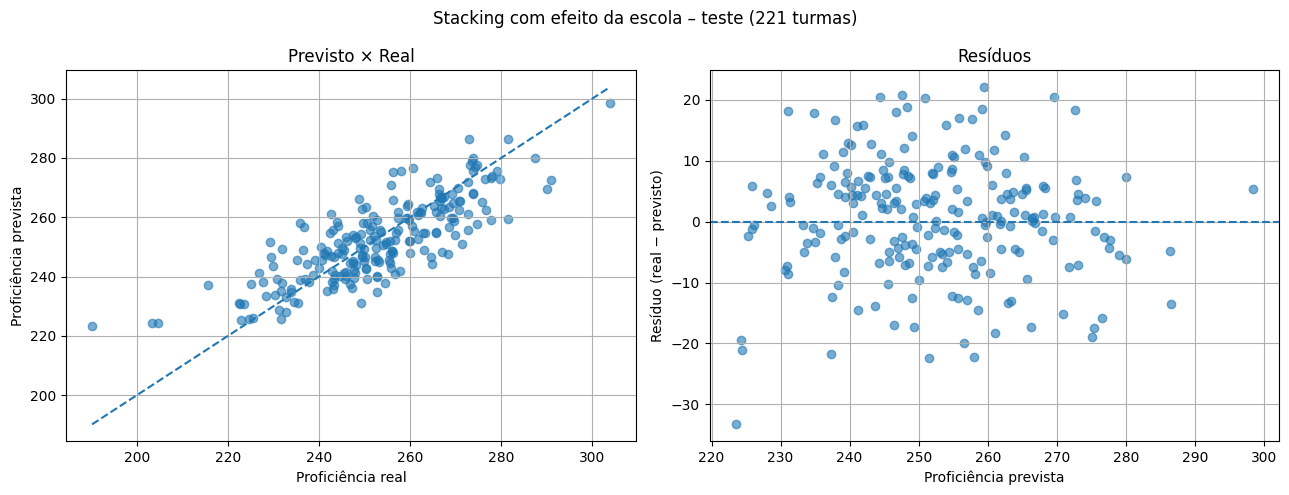

               |SHAP| médio (pontos)  Importância relativa %
INTERMEDIARIO                  4.642                  23.347
FINAL                          3.723                  18.724
INICIAL                        3.490                  17.549
Escola                         3.423                  17.215
ANO                            2.920                  14.686
TURNO                          1.686                   8.479
                                   Importância relativa %
Avaliações diagnósticas (3 notas)                    59.6
Escola                                               17.2
Ano e turno                                          23.2


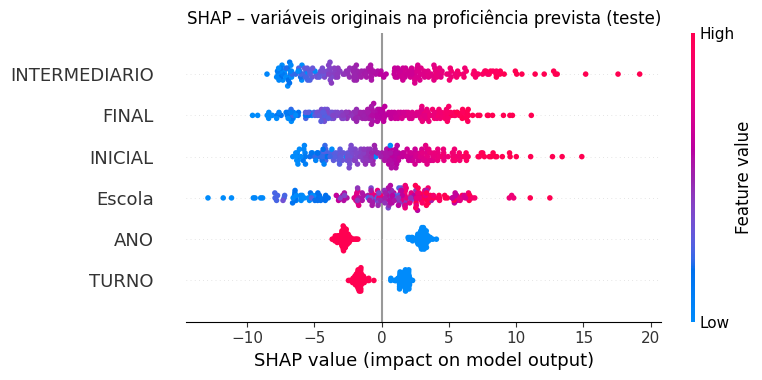

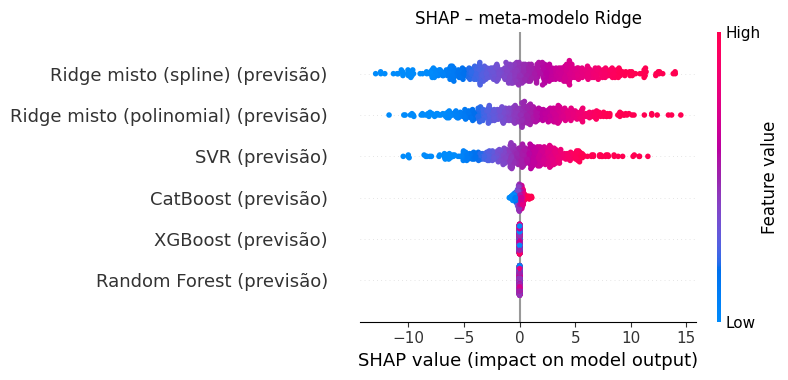

              Número de turmas (n)  Média Mediana     DP Mínimo  Máximo  IC 95% da média IC 95% da mediana (bootstrap)
INICIAL                         47  5.947   5.763  1.122  3.428   8.456  [5.618 ; 6.277]               [5.633 ; 6.331]
INTERMEDIARIO                   41  8.221   8.302  1.629   4.76  11.211  [7.707 ; 8.735]               [7.681 ; 8.883]
FINAL                           33  5.911   5.673  1.454  3.512   8.913  [5.395 ; 6.426]               [4.988 ; 6.597]


In [ ]:
#!/usr/bin/env python
# coding: utf-8

# # Stacking com efeito da escola
# Com só as três avaliações (INICIAL, INTERMEDIÁRIA, FINAL), o R² de teste fica em ≈ 0,59–0,60.
# A informação que mais acrescenta é **a escola**: turmas da mesma escola têm proficiências parecidas por fatores que
# as três notas não captam. Aqui a escola, o ano e o turno (M/T, última letra da TURMA) entram no modelo.
#
# - **Não** se usa a coluna DESEMPENHO: ela é calculada a partir da própria proficiência (vazamento).
# - O efeito da escola é aprendido **só com as turmas de treino**: Ridge com uma coluna por escola (efeito "encolhido",
#   como num modelo misto) e *target encoding* calculado dentro de cada dobra da validação cruzada.
# - Vale para prever **turmas novas de escolas que já estão nos dados**; para uma escola nova, o modelo volta a depender só das três notas.

# In[1]:


!pip install pandas numpy scikit-learn xgboost catboost openpyxl matplotlib shap
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer, OneHotEncoder, TargetEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, StackingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

# 1. Dados (valores decimais preservados, como no seu notebook)
dados = pd.read_excel('LP.dados.turma(01).xlsx')
NOTAS = ['INICIAL', 'INTERMEDIARIO', 'FINAL']
dados['TURNO'] = dados['TURMA'].str[-1]            # M = manhã, T = tarde
dados['ANO'] = dados['ANO'].astype(str)
CATEG = ['Escola', 'ANO', 'TURNO']
X = dados[NOTAS + CATEG]; y = dados['PROFICIENCIA']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)   # mesma divisão 70/30
print(f'Treino: {len(X_train)} turmas | Teste: {len(X_test)} turmas | {dados.Escola.nunique()} escolas')
print((X_train.head()).to_string())


# In[2]:


def metricas(nome, modelo, Xtr, Xte):
    cv = cross_validate(modelo, Xtr, y_train, cv=kf, scoring='r2', return_train_score=True, n_jobs=-1)
    tr, va = cv['train_score'].mean(), cv['test_score'].mean()
    p = modelo.fit(Xtr, y_train).predict(Xte)
    return {'Modelo': nome, 'R² treino (CV)': tr, 'R² validação (CV)': va, 'Gap treino–validação': tr - va,
            'R² teste': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p),
            'RMSE': np.sqrt(mean_squared_error(y_test, p)), 'MAPE (%)': np.mean(np.abs((y_test - p) / y_test)) * 100}, p

# ---------- A) seu stacking polinomial com seis modelos-base (só as três avaliações)
P = lambda m: make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), m)
stack_notas = StackingRegressor([(n, P(m)) for n, m in [
    ('rf', RandomForestRegressor(n_estimators=220, max_depth=5, min_samples_leaf=8, max_features=0.7, random_state=SEED, n_jobs=-1)),
    ('xgb', XGBRegressor(n_estimators=300, max_depth=2, learning_rate=0.03, min_child_weight=4, reg_lambda=8, subsample=0.85,
                         objective='reg:squarederror', random_state=SEED, n_jobs=-1)),
    ('catboost', CatBoostRegressor(iterations=180, depth=5, learning_rate=0.035, l2_leaf_reg=20, subsample=0.85,
                                   random_seed=SEED, verbose=False, allow_writing_files=False)),
    ('extra_trees', ExtraTreesRegressor(n_estimators=240, min_samples_leaf=10, max_features=0.8, random_state=SEED, n_jobs=-1)),
    ('svr', make_pipeline(StandardScaler(), SVR(C=12, epsilon=5, gamma='scale'))),
    ('ridge_base', make_pipeline(StandardScaler(), Ridge(alpha=15)))]],
    final_estimator=make_pipeline(StandardScaler(), Ridge(alpha=0.01)), cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
linha_a, p_a = metricas('Stacking – só as três avaliações', stack_notas, X_train[NOTAS], X_test[NOTAS])


# ### Stacking com efeito da escola – algoritmos combinados
# | Camada | Algoritmo | Entradas |
# |---|---|---|
# | Base | **Ridge misto (spline)** | notas → StandardScaler → SplineTransformer; Escola, ANO e TURNO → uma coluna por categoria; Ridge (α = 3) |
# | Base | **Ridge misto (polinomial)** | notas → PolynomialFeatures grau 2 → StandardScaler; Escola, ANO e TURNO → uma coluna por categoria; Ridge (α = 3) |
# | Base | **SVR** | notas + *target encoding* de Escola, ANO e TURNO → StandardScaler → SVR (RBF) |
# | Base | **Random Forest** | notas + *target encoding* |
# | Base | **XGBoost** | notas + *target encoding* |
# | Base | **CatBoost** | notas + *target encoding* |
# | Meta | **Ridge** (pesos positivos) | previsões dos 6 modelos-base |

# In[3]:


# ---------- B) stacking com efeito da escola
def ridge_misto(notas):
    num = (Pipeline([('scaler', StandardScaler()), ('spline', SplineTransformer(n_knots=5, degree=3))]) if notas == 'spline'
           else Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)), ('scaler', StandardScaler())]))
    return Pipeline([('prep', ColumnTransformer([('notas', num, NOTAS),
                                                 ('categ', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEG)])),
                     ('model', Ridge(alpha=3.0))])

def com_target_encoding(modelo, escalar=False):
    # o target encoding é recalculado dentro de cada dobra, só com as turmas de treino daquela dobra
    passos = [('prep', ColumnTransformer([('notas', 'passthrough', NOTAS), ('categ', TargetEncoder(random_state=SEED), CATEG)]))]
    if escalar: passos.append(('scaler', StandardScaler()))
    return Pipeline(passos + [('model', modelo)])

stack_escola = StackingRegressor([
    ('Ridge misto (spline)', ridge_misto('spline')),
    ('Ridge misto (polinomial)', ridge_misto('poly')),
    ('SVR', com_target_encoding(SVR(C=50, epsilon=2), escalar=True)),
    ('Random Forest', com_target_encoding(RandomForestRegressor(n_estimators=400, max_depth=8, min_samples_leaf=10,
                                                                max_features=1.0, random_state=SEED, n_jobs=-1))),
    ('XGBoost', com_target_encoding(XGBRegressor(n_estimators=500, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                 reg_lambda=10, min_child_weight=5, random_state=SEED, n_jobs=-1))),
    ('CatBoost', com_target_encoding(CatBoostRegressor(iterations=800, depth=4, learning_rate=0.05, l2_leaf_reg=5,
                                                       subsample=0.8, random_state=SEED, verbose=0)))],
    final_estimator=Ridge(alpha=1.0, positive=True), cv=5, n_jobs=-1)
linha_b, p_b = metricas('Stacking – avaliações + escola, ano e turno', stack_escola, X_train, X_test)

print((pd.DataFrame([linha_a, linha_b]).set_index('Modelo').round(4)).to_string())
print('Pesos do meta-modelo Ridge:',
      dict(zip([n for n, _ in stack_escola.estimators], [round(float(c), 3) for c in stack_escola.final_estimator_.coef_])))


# In[4]:


fig, ax = plt.subplots(1, 2, figsize=(13, 5)); fig.suptitle('Stacking com efeito da escola – teste (221 turmas)')
ax[0].scatter(y_test, p_b, alpha=.6); ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--')
ax[0].set(xlabel='Proficiência real', ylabel='Proficiência prevista', title='Previsto × Real')
ax[1].scatter(p_b, y_test - p_b, alpha=.6); ax[1].axhline(0, ls='--')
ax[1].set(xlabel='Proficiência prevista', ylabel='Resíduo (real − previsto)', title='Resíduos')
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()


# ## SHAP – o que pesa na proficiência prevista
# Dois níveis, como na dissertação:
# 1. **Variáveis originais** (INICIAL, INTERMEDIÁRIA, FINAL, Escola, ANO, TURNO): quanto cada uma desloca a proficiência prevista
#    pelo stacking completo, em pontos de proficiência (`KernelExplainer` sobre o stacking inteiro, no conjunto de teste).
# 2. **Meta-modelo Ridge**: quanto cada modelo-base pesa na previsão final.
#
# No gráfico de enxame, a cor da Escola representa a proficiência média dessa escola no treino (vermelho = escola de média alta),
# porque o nome da escola não tem uma ordem natural.

# In[5]:


import shap
VARS = NOTAS + CATEG
cod = {c: {v: i for i, v in enumerate(sorted(X[c].unique()))} for c in CATEG}      # categorias → códigos numéricos
inv = {c: {i: v for v, i in cod[c].items()} for c in CATEG}

def para_codigos(D):
    D = D.copy()
    for c in CATEG: D[c] = D[c].map(cod[c])
    return D.astype(float)

def prever_codigos(Z):
    D = pd.DataFrame(Z, columns=VARS)
    for c in CATEG: D[c] = D[c].round().astype(int).map(inv[c])
    return stack_escola.predict(D)

fundo = para_codigos(X_train.sample(100, random_state=SEED))
exp = shap.KernelExplainer(prever_codigos, fundo)
sv = exp.shap_values(para_codigos(X_test), silent=True)

# importância global e por grupo
imp = pd.DataFrame({'|SHAP| médio (pontos)': np.abs(sv).mean(0)}, index=VARS)
imp['Importância relativa %'] = 100 * imp.iloc[:, 0] / imp.iloc[:, 0].sum()
print((imp.sort_values('|SHAP| médio (pontos)', ascending=False).round(3)).to_string())
grupos = {'Avaliações diagnósticas (3 notas)': NOTAS, 'Escola': ['Escola'], 'Ano e turno': ['ANO', 'TURNO']}
print(pd.Series({g: imp.loc[v, 'Importância relativa %'].sum() for g, v in grupos.items()},
                  name='Importância relativa %').round(1).to_frame().to_string())

# gráfico de enxame (cor da Escola = média da escola no treino)
media_escola = y_train.groupby(X_train['Escola']).mean()
cor = X_test[VARS].copy()
cor['Escola'] = X_test['Escola'].map(media_escola); cor['ANO'] = cor['ANO'].astype(int)
cor['TURNO'] = (cor['TURNO'] == 'T').astype(int)
shap.summary_plot(sv, cor, show=False)
plt.title('SHAP – variáveis originais na proficiência prevista (teste)'); plt.tight_layout(); plt.show()


# In[6]:


# Nível 1 – meta-modelo Ridge: peso de cada modelo-base
bases = dict(zip([n for n, _ in stack_escola.estimators], stack_escola.estimators_))
X_meta = pd.DataFrame({f'{n} (previsão)': m.predict(X_train) for n, m in bases.items()}, index=X_train.index)
exp_meta = shap.KernelExplainer(stack_escola.final_estimator_.predict, X_meta.sample(100, random_state=SEED))
shap.summary_plot(exp_meta.shap_values(X_meta, silent=True), X_meta, show=False)
plt.title('SHAP – meta-modelo Ridge'); plt.tight_layout(); plt.show()


# ## Simulação contrafactual: +10 p.p. em cada avaliação (turmas do teste entre 55% e 60%)
# Escola, ano, turno e as outras duas avaliações ficam constantes. Δ = ŷ₁ − ŷ₀ é o que o **modelo** prevê,
# não o efeito causal de uma intervenção.

# In[7]:


from scipy import stats
def contrafactual(var, faixa=(55, 60), inc=10, B=5000):
    S = X_test[(X_test[var] >= faixa[0]) & (X_test[var] <= faixa[1])]
    S1 = S.copy(); S1[var] = np.minimum(100, S1[var] + inc)
    d = stack_escola.predict(S1) - stack_escola.predict(S)
    n, m, dp = len(d), d.mean(), d.std(ddof=1)
    ic = stats.t.interval(.95, n - 1, loc=m, scale=dp / np.sqrt(n))
    rng = np.random.default_rng(SEED); med = np.percentile([np.median(rng.choice(d, n)) for _ in range(B)], [2.5, 97.5])
    return {'Número de turmas (n)': n, 'Média': round(m, 3), 'Mediana': round(float(np.median(d)), 3), 'DP': round(dp, 3),
            'Mínimo': round(d.min(), 3), 'Máximo': round(d.max(), 3),
            'IC 95% da média': f'[{ic[0]:.3f} ; {ic[1]:.3f}]', 'IC 95% da mediana (bootstrap)': f'[{med[0]:.3f} ; {med[1]:.3f}]'}
print((pd.DataFrame({v: contrafactual(v) for v in NOTAS}).T).to_string())

In [ ]:
from google.colab import drive
drive.mount('/content/drive')